In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device in use:', device)

Device in use: cuda


In [3]:
def prepare_data(data_dir):
    filepaths = []
    labels = []
    
    folds = os.listdir(data_dir)
    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        if os.path.isdir(foldpath):
            filelist = os.listdir(foldpath)
            for file in filelist:
                filepath = os.path.join(foldpath, file)
                filepaths.append(filepath)
                labels.append(fold)
    
    df = pd.DataFrame(data={'filepaths': filepaths, 'labels': labels})
    return df

In [5]:
data_dir = 'dataset/crop'
df = prepare_data(data_dir)
print(f'Shape of dataset is {df.shape}, numbers of labels {df["labels"].nunique()}')
df.head()

Shape of dataset is (45435, 2), numbers of labels 114


,filepaths,labels
0,dataset/crop\A10\00c09f406d31a0cd9402862fbd26d...,A10
1,dataset/crop\A10\00d4b7ea93ca1417393007c61c519...,A10
2,dataset/crop\A10\01169f9ba735dfcb46dab62bc5649...,A10
3,dataset/crop\A10\016fd73cdece1b76562ec526ba939...,A10
4,dataset/crop\A10\01ed4d81c5d733cbaa266b6ea7821...,A10


In [6]:
train, test = train_test_split(df, test_size=0.3, stratify=df['labels'], random_state=42)
test, valid = train_test_split(test, test_size=0.5, stratify=test['labels'], random_state=42)
train.shape, test.shape, valid.shape

((31804, 2), (6815, 2), (6816, 2))

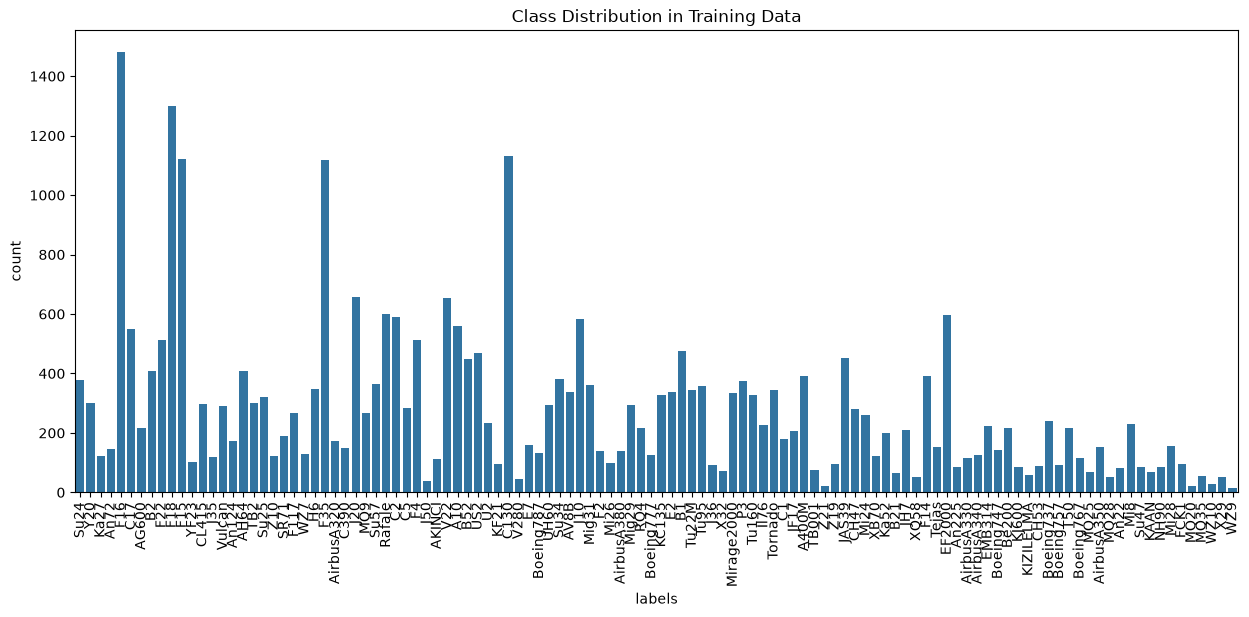

In [7]:
# Class Distribution
plt.figure(figsize=(15, 6))
sns.countplot(data=train, x='labels')
plt.title('Class Distribution in Training Data')
plt.xticks(rotation=90)
plt.show()

In [8]:
batch_size = 16
img_size = (224, 224)

# Słownik mapujący nazwy klas na indeksy (odpowiednik train_gen.class_indices)
unique_labels = sorted(train['labels'].unique())
class_indices = {label: i for i, label in enumerate(unique_labels)}

class AircraftDataset(Dataset):
    def __init__(self, dataframe, class_to_idx, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepaths']
        label_str = self.df.loc[idx, 'labels']
        label = self.class_to_idx[label_str]
        
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
            
        return image, label

transform = transforms.Compose([
    transforms.Resize(img_size),
    transforms.ToTensor()
])

train_dataset = AircraftDataset(train, class_indices, transform=transform)
valid_dataset = AircraftDataset(valid, class_indices, transform=transform)
test_dataset = AircraftDataset(test, class_indices, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

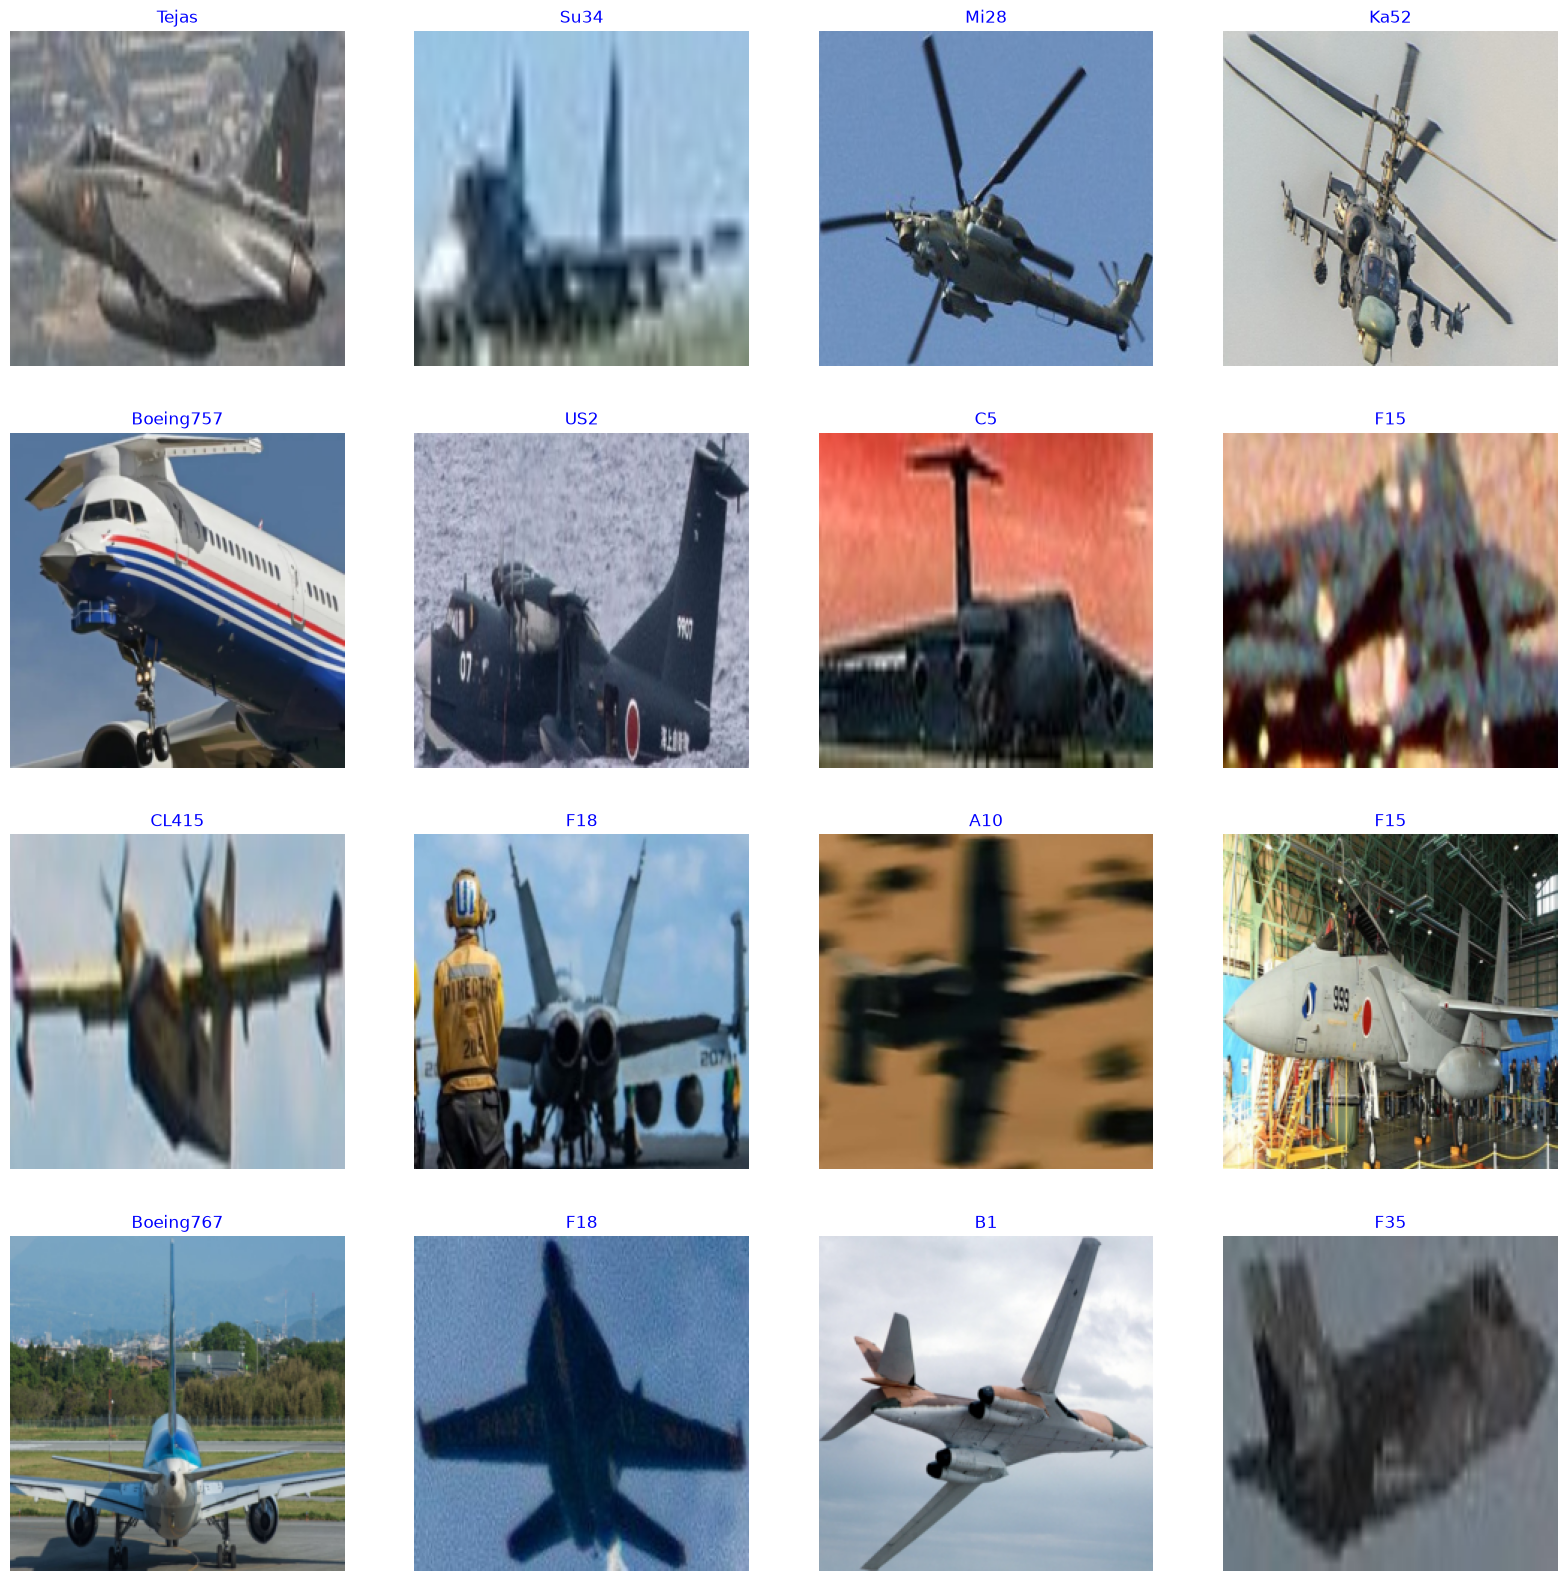

In [9]:
g_dict = class_indices
classes = list(g_dict.keys())

# Get a batch of samples
images, labels = next(iter(train_loader))

plt.figure(figsize=(20, 20))

for i in range(min(16, len(images))):
    plt.subplot(4, 4, i + 1)
    # PyTorch Tensors są w formacie (C, H, W) -> zamiana na (H, W, C) do wyświetlenia
    image = images[i].permute(1, 2, 0).numpy()
    plt.imshow(image)
    index = labels[i].item()
    class_name = classes[index]
    plt.title(class_name, color='blue', fontsize=12)
    plt.axis('off')
plt.show()

In [10]:
channels = 3
img_shape = (channels, img_size[0], img_size[1])
class_count = len(classes)

class CustomEfficientNetB3(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        # Backbone z global pooling (pooling='max')
        self.base_model = timm.create_model('efficientnet_b3', pretrained=True, num_classes=0, global_pool='max')
        num_features = self.base_model.num_features
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.base_model(x)
        x = self.classifier(x)
        return x

model = CustomEfficientNetB3(num_classes=class_count).to(device)

optimizer = torch.optim.Adamax(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

print(model)

CustomEfficientNetB3(
  (base_model): EfficientNet(
    (conv_stem): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
          (bn1): BatchNormAct2d(
            40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
         

In [12]:
from tqdm import tqdm

class EarlyStoppingPyTorch:
    def __init__(self, patience=3, restore_best_weights=True):
        self.patience = patience
        self.restore_best_weights = restore_best_weights
        self.best_loss = float('inf')
        self.counter = 0
        self.best_state = None
        self.early_stop = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.counter = 0
            if self.restore_best_weights:
                self.best_state = model.state_dict()
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
                if self.restore_best_weights and self.best_state is not None:
                    model.load_state_dict(self.best_state)

early_stopping = EarlyStoppingPyTorch(patience=3, restore_best_weights=True)

epochs = 20
history = {'accuracy': [], 'loss': [], 'val_accuracy': [], 'val_loss': []}

for epoch in range(epochs):
    # Training phase
    model.train()
    running_loss, running_corrects, total_samples = 0.0, 0, 0
    
    # Pasek postępu dla treningu
    train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False)
    for inputs, labels in train_loop:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        _, preds = torch.max(outputs, 1)
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data).item()
        total_samples += inputs.size(0)
        
        # Aktualizacja paska postępu bieżącymi wynikami
        train_loop.set_postfix(loss=loss.item())
        
    epoch_loss = running_loss / total_samples
    epoch_acc = running_corrects / total_samples
    
    # Validation phase
    model.eval()
    val_running_loss, val_running_corrects, val_total_samples = 0.0, 0, 0
    
    # Pasek postępu dla walidacji
    valid_loop = tqdm(valid_loader, desc=f"Epoch {epoch+1}/{epochs} [Valid]", leave=False)
    with torch.no_grad():
        for inputs, labels in valid_loop:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            _, preds = torch.max(outputs, 1)
            val_running_loss += loss.item() * inputs.size(0)
            val_running_corrects += torch.sum(preds == labels.data).item()
            val_total_samples += inputs.size(0)
            
            valid_loop.set_postfix(val_loss=loss.item())
            
    val_loss = val_running_loss / val_total_samples
    val_acc = val_running_corrects / val_total_samples
    
    history['accuracy'].append(epoch_acc)
    history['loss'].append(epoch_loss)
    history['val_accuracy'].append(val_acc)
    history['val_loss'].append(val_loss)
    
    print(f'Epoch {epoch+1}/{epochs} - loss: {epoch_loss:.4f} - accuracy: {epoch_acc:.4f} - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
    
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print(f"Early stopping triggered at epoch {epoch+1}")
        break

Epoch 1/20 - loss: 2.6746 - accuracy: 0.3727 - val_loss: 1.4749 - val_accuracy: 0.6309


Epoch 2/20 - loss: 1.3005 - accuracy: 0.6574 - val_loss: 1.0529 - val_accuracy: 0.7309


Epoch 3/20 - loss: 0.7681 - accuracy: 0.7873 - val_loss: 0.8665 - val_accuracy: 0.7815


Epoch 4/20 - loss: 0.4908 - accuracy: 0.8607 - val_loss: 0.8174 - val_accuracy: 0.8021


Epoch 5/20 - loss: 0.3293 - accuracy: 0.9036 - val_loss: 0.9284 - val_accuracy: 0.8050


Epoch 6/20 - loss: 0.2400 - accuracy: 0.9286 - val_loss: 0.8816 - val_accuracy: 0.8107


Epoch 7/20 - loss: 0.1893 - accuracy: 0.9447 - val_loss: 0.9218 - val_accuracy: 0.8150
Early stopping triggered at epoch 7


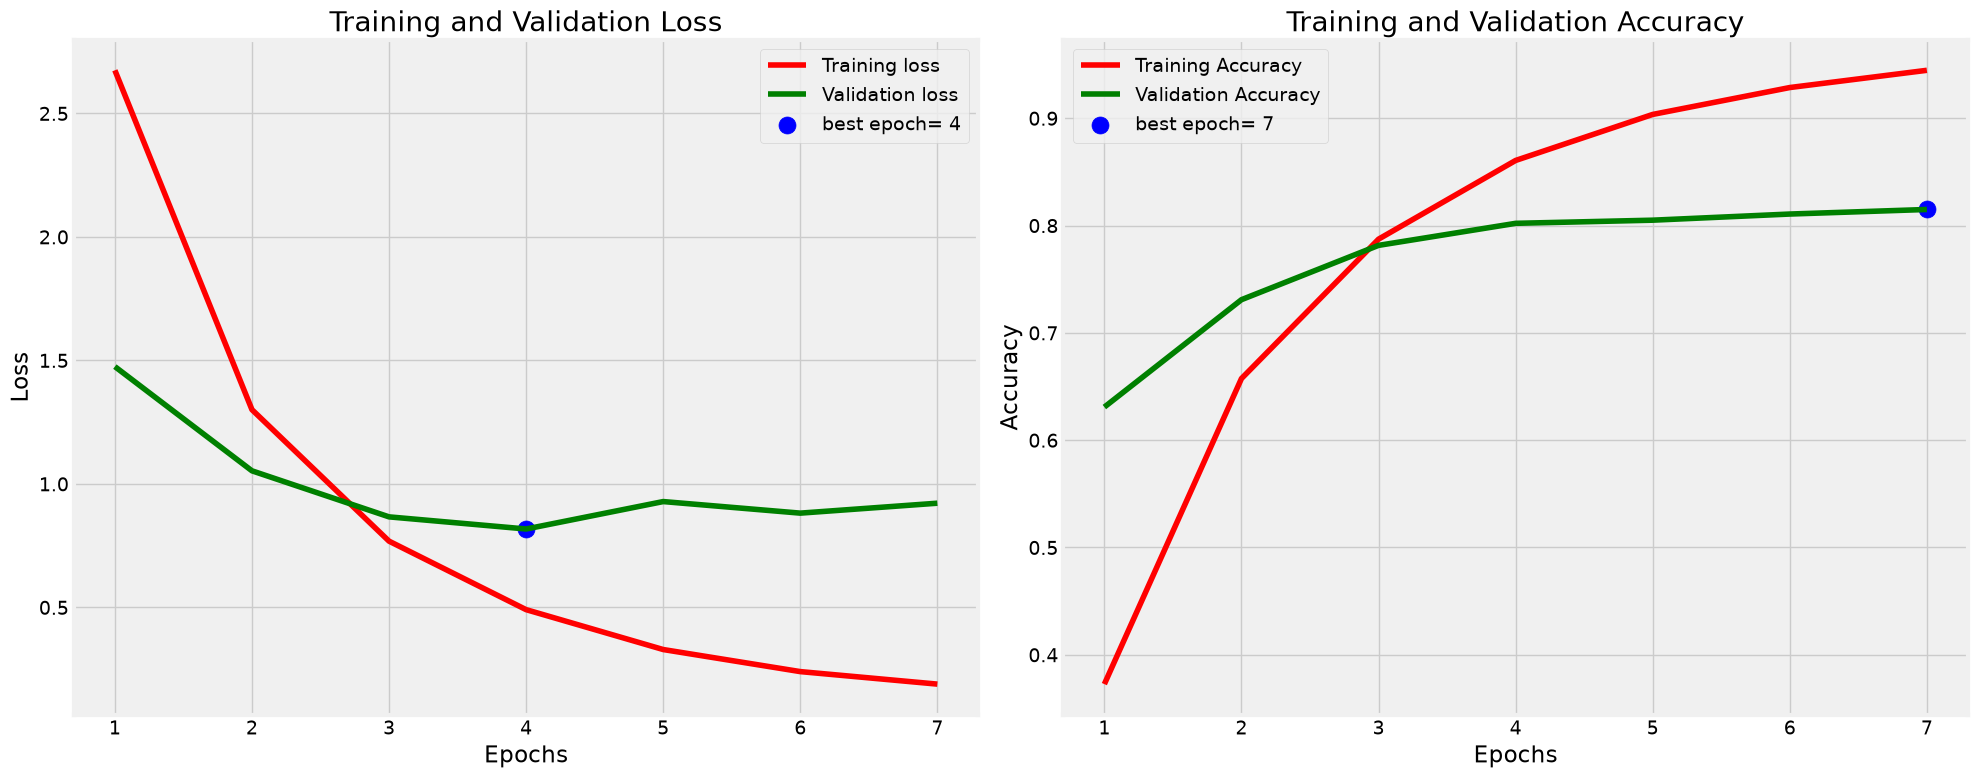

In [13]:
# Plot Accuracy and Loss
tr_acc = history['accuracy']
tr_loss = history['loss']
val_acc = history['val_accuracy']
val_loss = history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]

Epochs = [i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(index_loss + 1)}'
acc_label = f'best epoch= {str(index_acc + 1)}'

# Plot training history
plt.figure(figsize=(20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label='Training loss')
plt.plot(Epochs, val_loss, 'g', label='Validation loss')
plt.scatter(index_loss + 1, val_lowest, s=150, c='blue', label=loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label='Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label='Validation Accuracy')
plt.scatter(index_acc + 1, acc_highest, s=150, c='blue', label=acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
def evaluate_loader(loader):
    model.eval()
    running_loss, running_corrects, total_samples = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data).item()
            total_samples += inputs.size(0)
            
    return running_loss / total_samples, running_corrects / total_samples

train_score = evaluate_loader(train_loader)
valid_score = evaluate_loader(valid_loader)
test_score = evaluate_loader(test_loader)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Validation Loss: ", valid_score[0])
print("Validation Accuracy: ", valid_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

Train Loss:  0.05508921992688559
Train Accuracy:  0.9839642812224877
--------------------
Validation Loss:  0.9218153655889746
Validation Accuracy:  0.814994131455399
--------------------
Test Loss:  0.8905851709453481
Test Accuracy:  0.8171680117388115


In [15]:
# Get Predictions
model.eval()
all_preds = []
with torch.no_grad():
    for inputs, _ in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = torch.softmax(outputs, dim=1)
        all_preds.append(preds.cpu().numpy())

preds = np.concatenate(all_preds, axis=0)
y_pred = np.argmax(preds, axis=1)
classes = list(class_indices.keys())

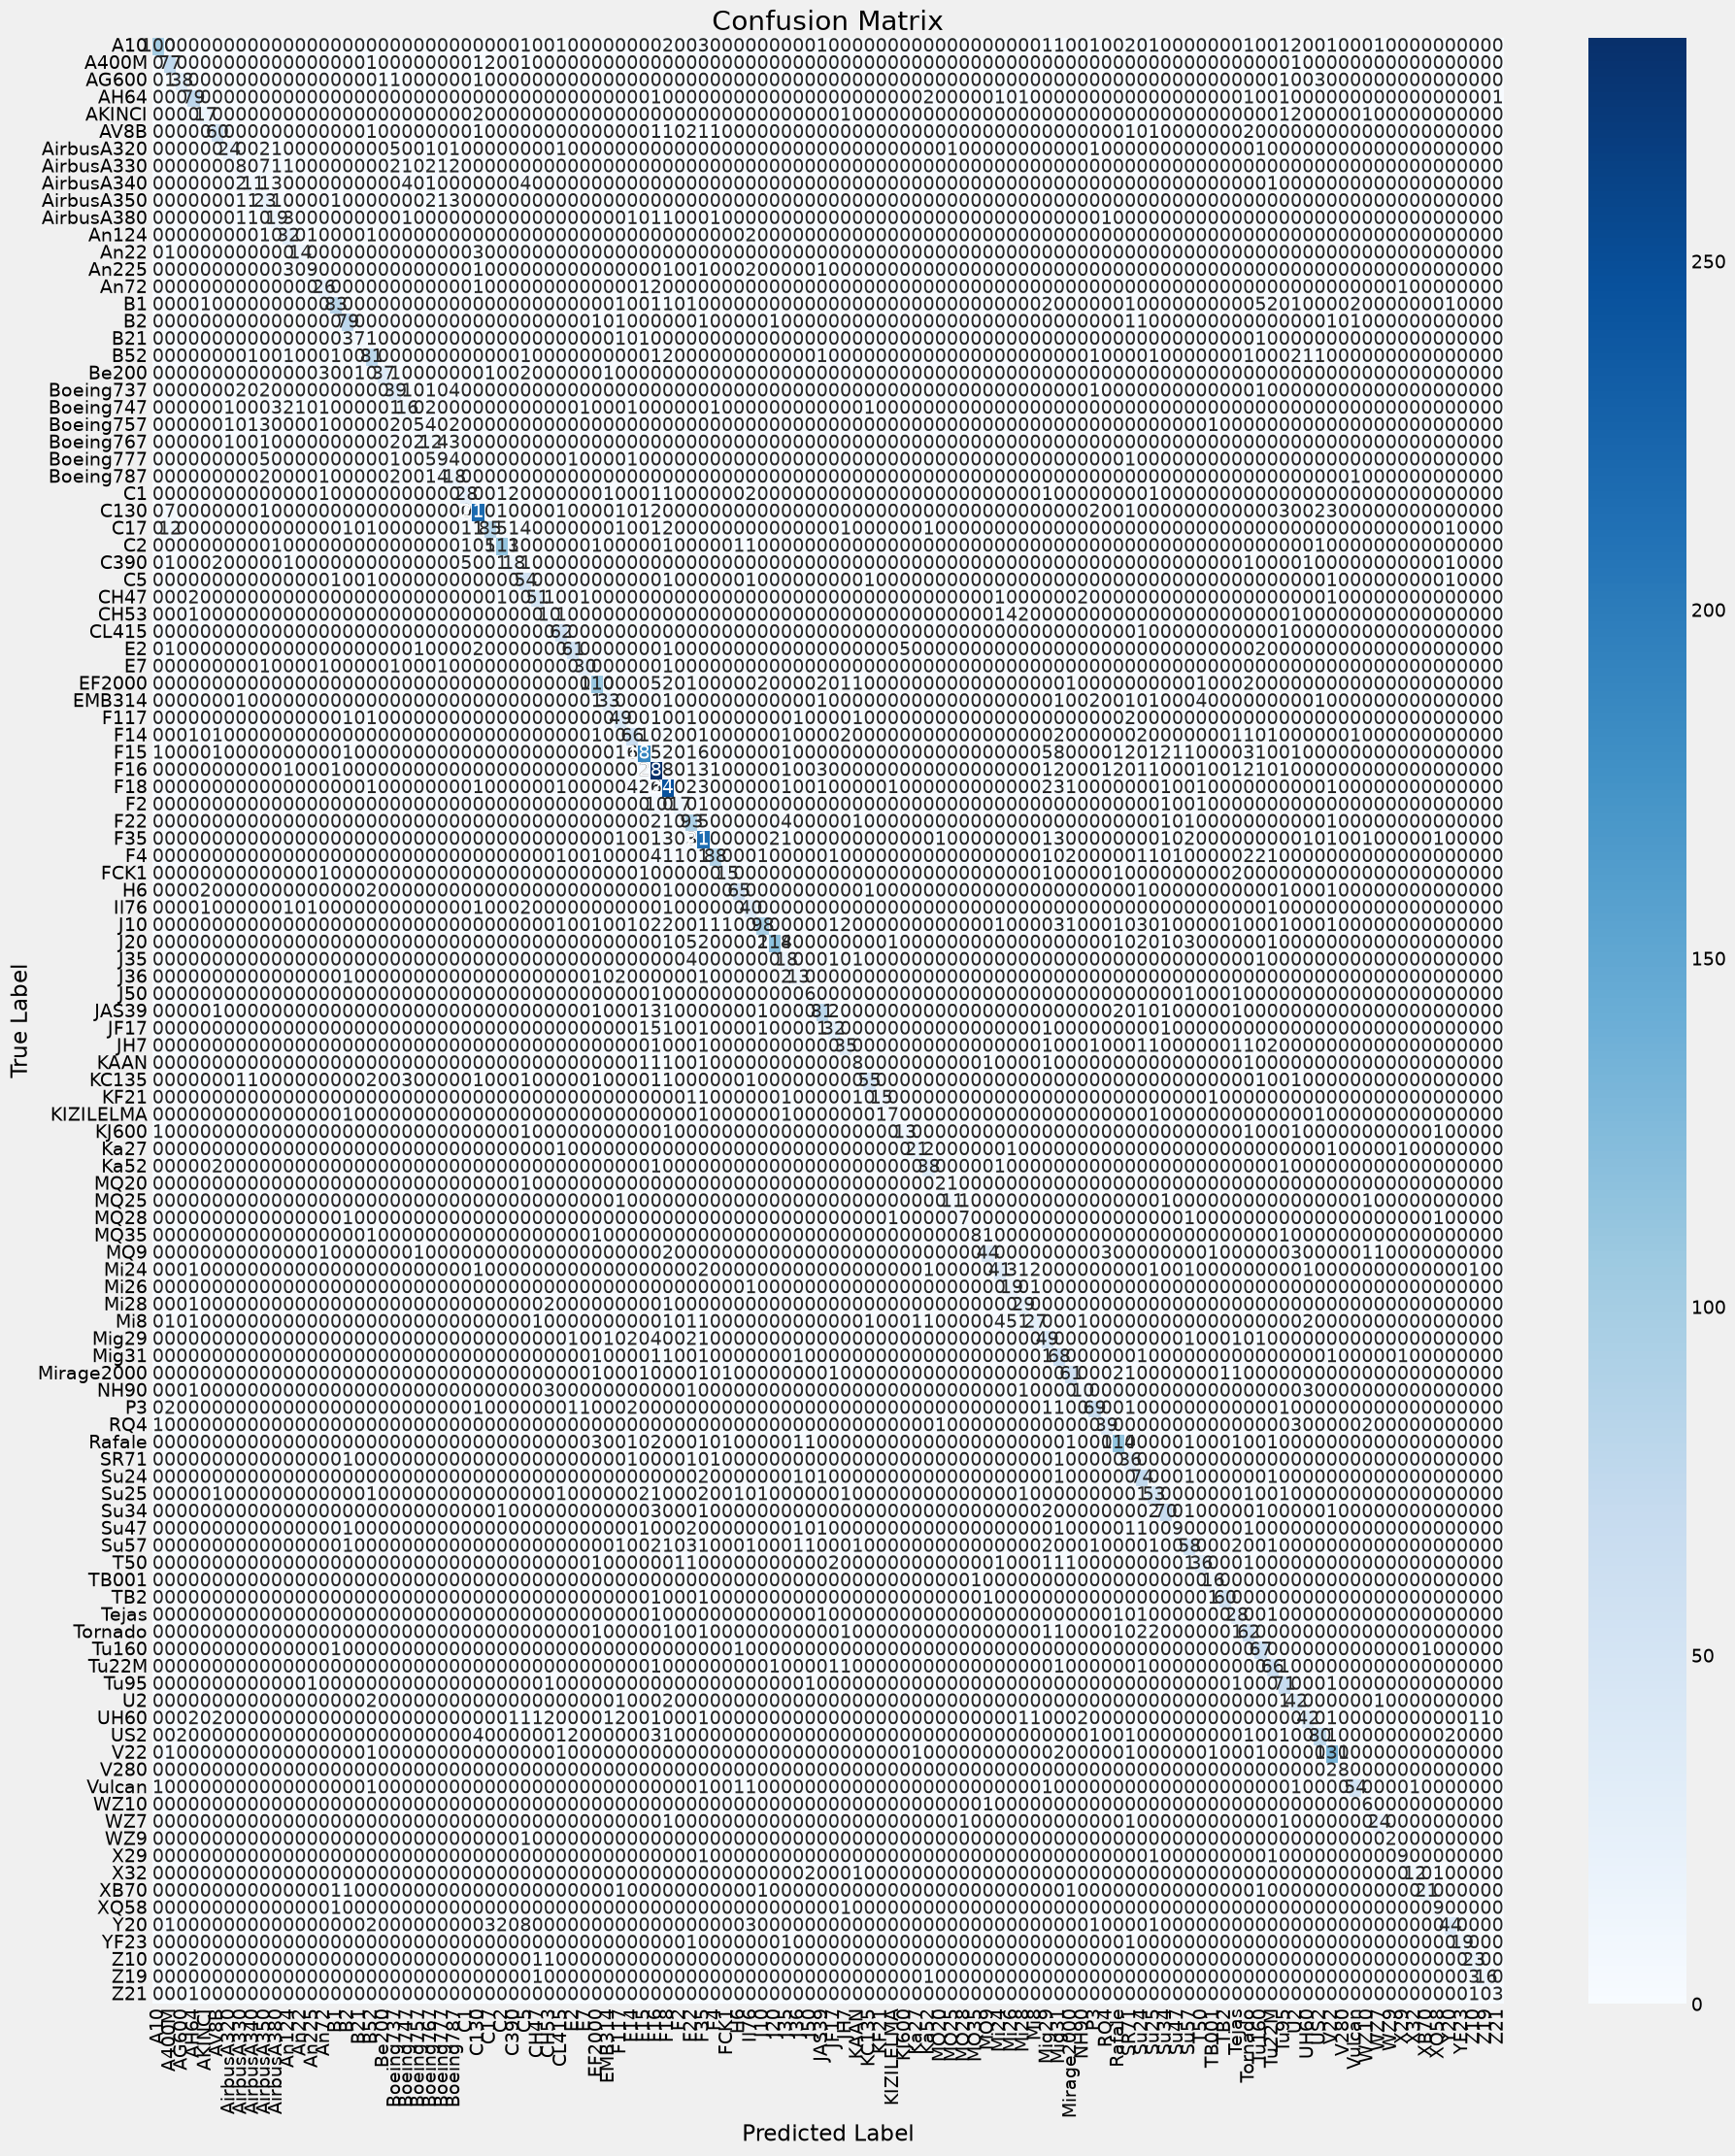

              precision    recall  f1-score   support

         A10       0.96      0.83      0.89       120
       A400M       0.73      0.93      0.82        83
       AG600       0.95      0.83      0.88        46
        AH64       0.86      0.91      0.88        87
      AKINCI       0.81      0.71      0.76        24
        AV8B       0.86      0.83      0.85        72
  AirbusA320       0.89      0.63      0.74        38
  AirbusA330       0.50      0.32      0.39        25
  AirbusA340       0.69      0.41      0.51        27
  AirbusA350       0.47      0.70      0.56        33
  AirbusA380       0.66      0.63      0.64        30
       An124       0.71      0.86      0.78        37
        An22       0.93      0.78      0.85        18
       An225       0.75      0.50      0.60        18
        An72       0.72      0.84      0.78        31
          B1       0.92      0.81      0.86       102
          B2       0.86      0.91      0.88        87
         B21       0.88    

In [16]:
# Confusion Matrix
plt.figure(figsize=(20, 25))
test_targets = test_dataset.df['labels'].map(class_indices).values
cm = confusion_matrix(test_targets, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Classification report
print(classification_report(test_targets, y_pred, target_names=classes))

In [17]:
torch.save(model.state_dict(), 'military_aircraft_classification.pth')